# 2017 — The Transformer: "Attention Is All You Need"

**Paper:** Ashish Vaswani et al., *"Attention Is All You Need"* (NeurIPS 2017).

The Transformer drops recurrence entirely. Every token attends to every other token in parallel:

$$\operatorname{Attention}(Q,K,V) = \operatorname{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}} + M\right)V$$

Components (all built from scratch below):
- **Scaled dot-product attention** with masks $M$ (padding / causal)
- **Multi-head attention:** $h$ attention heads in parallel subspaces
- **Sinusoidal positional encoding**, since attention by itself ignores order
- **Residual connections + LayerNorm** around each sub-layer, plus a position-wise **feed-forward** net
- **Encoder–decoder** with cross-attention

Task: **reverse and increment** a digit sequence (`3 1 4` → `5 2 4`, each digit +1 mod 10, order reversed). It needs content-based lookups at positions far apart, which is easy for attention.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        self.h, self.dk = h, d // h
        self.q, self.k, self.v, self.o = (nn.Linear(d, d) for _ in range(4))
        self.attn = None

    def forward(self, xq, xkv, mask=None):
        B, Tq, D = xq.shape; Tk = xkv.shape[1]
        split = lambda t, T: t.view(B, T, self.h, self.dk).transpose(1, 2)        # (B, h, T, dk)
        q, k, v = split(self.q(xq), Tq), split(self.k(xkv), Tk), split(self.v(xkv), Tk)
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.dk)                       # (B, h, Tq, Tk)
        if mask is not None: scores = scores.masked_fill(~mask, float("-inf"))
        a = scores.softmax(-1); self.attn = a.detach()
        return self.o((a @ v).transpose(1, 2).reshape(B, Tq, D))

def sinusoidal(T, d):
    pos = torch.arange(T)[:, None]; i = torch.arange(0, d, 2)
    pe = torch.zeros(T, d)
    pe[:, 0::2] = torch.sin(pos / 10000 ** (i / d)); pe[:, 1::2] = torch.cos(pos / 10000 ** (i / d))
    return pe

class EncoderLayer(nn.Module):
    def __init__(self, d, h, ff, p=0.1):
        super().__init__()
        self.sa, self.ff = MultiHeadAttention(d, h), nn.Sequential(nn.Linear(d, ff), nn.ReLU(), nn.Linear(ff, d))
        self.n1, self.n2, self.drop = nn.LayerNorm(d), nn.LayerNorm(d), nn.Dropout(p)
    def forward(self, x, mask):
        x = self.n1(x + self.drop(self.sa(x, x, mask)))        # post-norm, as in the original paper
        return self.n2(x + self.drop(self.ff(x)))

class DecoderLayer(nn.Module):
    def __init__(self, d, h, ff, p=0.1):
        super().__init__()
        self.sa, self.ca = MultiHeadAttention(d, h), MultiHeadAttention(d, h)
        self.ff = nn.Sequential(nn.Linear(d, ff), nn.ReLU(), nn.Linear(ff, d))
        self.n1, self.n2, self.n3, self.drop = nn.LayerNorm(d), nn.LayerNorm(d), nn.LayerNorm(d), nn.Dropout(p)
    def forward(self, y, mem, causal):
        y = self.n1(y + self.drop(self.sa(y, y, causal)))       # masked self-attention
        y = self.n2(y + self.drop(self.ca(y, mem)))             # cross-attention to the encoder output
        return self.n3(y + self.drop(self.ff(y)))

class Transformer(nn.Module):
    def __init__(self, V, d=128, h=4, ff=256, n=2, max_len=64):
        super().__init__()
        self.emb = nn.Embedding(V, d); self.d = d
        self.register_buffer("pe", sinusoidal(max_len, d))
        self.enc = nn.ModuleList([EncoderLayer(d, h, ff) for _ in range(n)])
        self.dec = nn.ModuleList([DecoderLayer(d, h, ff) for _ in range(n)])
        self.out = nn.Linear(d, V)

    def embed(self, x): return self.emb(x) * math.sqrt(self.d) + self.pe[: x.shape[1]]

    def forward(self, src, tgt_in):
        mem = self.embed(src)
        for l in self.enc: mem = l(mem, None)
        T = tgt_in.shape[1]
        causal = torch.tril(torch.ones(T, T, dtype=torch.bool, device=src.device))   # no peeking at the future
        y = self.embed(tgt_in)
        for l in self.dec: y = l(y, mem, causal)
        return self.out(y)

    @torch.no_grad()
    def generate(self, src, n):
        tgt = torch.full((len(src), 1), BOS, device=src.device)
        for _ in range(n):
            tgt = torch.cat([tgt, self(src, tgt)[:, -1:].argmax(-1)], 1)
        return tgt[:, 1:]

In [3]:
BOS, V, L = 10, 11, 12
def batch(B, L=L):
    x = torch.randint(0, 10, (B, L), device=device)
    y = ((x + 1) % 10).flip(1)
    return x, y

model = Transformer(V).to(device)
print("parameters:", sum(p.numel() for p in model.parameters()))
steps = 1500
opt = torch.optim.Adam(model.parameters(), lr=2e-3, betas=(0.9, 0.98), eps=1e-9)
# The paper used linear warmup + inverse-sqrt decay (and label smoothing 0.1). For a short toy run,
# warmup + cosine decay (one-cycle) converges faster; warmup is the essential part for post-norm Transformers.
sched = torch.optim.lr_scheduler.OneCycleLR(opt, 2e-3, total_steps=steps, pct_start=0.1)
for step in range(steps):
    model.train()
    x, y = batch(128)
    tgt_in = torch.cat([torch.full_like(y[:, :1], BOS), y[:, :-1]], 1)
    loss = F.cross_entropy(model(x, tgt_in).reshape(-1, V), y.reshape(-1))
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    if step % 300 == 0 or step == steps - 1:
        model.eval(); xt, yt = batch(500); pred = model.generate(xt, L)
        print(f"step {step:4d} loss {loss.item():.3f} | full-sequence accuracy {(pred == yt).all(1).float().mean():.3f}")

parameters: 665355


step    0 loss 2.487 | full-sequence accuracy 0.000


step  300 loss 1.010 | full-sequence accuracy 0.000


step  600 loss 0.253 | full-sequence accuracy 0.482


step  900 loss 0.068 | full-sequence accuracy 0.886


step 1200 loss 0.021 | full-sequence accuracy 0.988


step 1499 loss 0.003 | full-sequence accuracy 1.000


## Cross-attention reveals the algorithm
Output position $t$ should look at input position $L-1-t$, which shows up as an anti-diagonal.

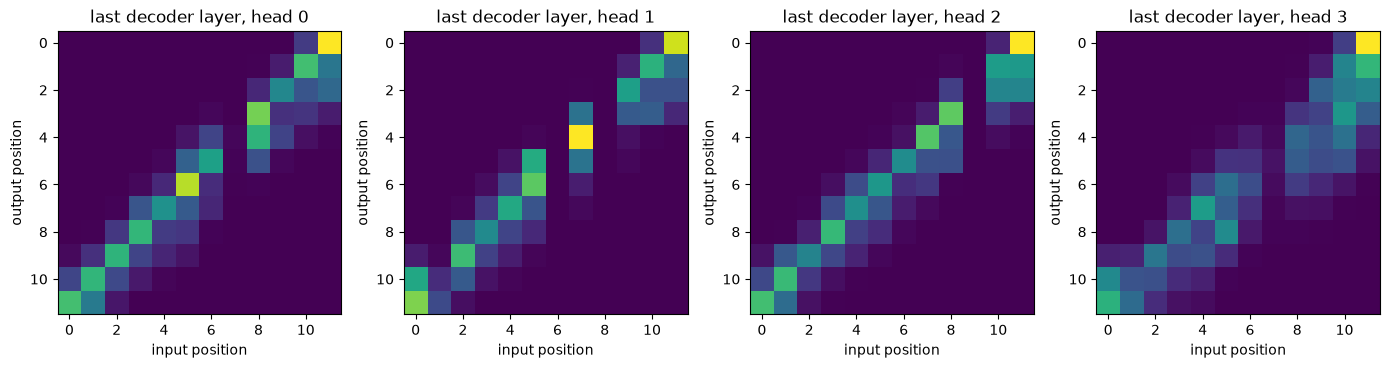

input : [0, 7, 8, 3, 0, 8, 9, 5, 9, 6, 8, 4]


output: [5, 9, 7, 0, 6, 0, 9, 1, 4, 9, 8, 1]


In [4]:
model.eval()
x, y = batch(1)
tgt_in = torch.cat([torch.full_like(y[:, :1], BOS), y[:, :-1]], 1)
with torch.no_grad(): model(x, tgt_in)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for hd in range(4):
    axes[hd].imshow(model.dec[-1].ca.attn[0, hd].cpu(), cmap="viridis")
    axes[hd].set(title=f"last decoder layer, head {hd}", xlabel="input position", ylabel="output position")
plt.tight_layout(); plt.show()
print("input :", x[0].tolist()); print("output:", model.generate(x, L)[0].tolist())